# 출처 검증형 deep research

**이 노트북에서 할 일**

1. 교재용 자료 셋을 손 요청으로 상태 칸 `files`에 넣고, 파일 도구로 찾는 모양을 봅니다.
2. 답 글의 출처 표시가 실제로 있는 파일을 가리키는지 코드로 판정하는 함수를 만듭니다.
3. 실제 모델에게 자료를 찾아 답하게 하고, 그 답의 출처 표시를 판정합니다.

**준비물** — 프로젝트 폴더의 `.env` 파일에 `OPENAI_API_KEY`가 있어야 합니다.
모델은 `gpt-5.4-mini`이고, 5절에서 조사 에이전트를 한 번 실행합니다.
노트북 밖에서 같은 질문을 다섯 번 보냈을 때, 요청은 다섯 번 모두 3번이었습니다.
서브에이전트는 쓰지 않고, 호출 한도는 조사 에이전트 10, general-purpose 2로 줍니다.
요금표로 어림한 예상 비용은 한 번 실행에 0.01달러 아래이고, 청구 금액이 아닙니다.

파일은 상태 칸 `files`에만 두고, 디스크에는 쓰지 않습니다.
웹 검색은 하지 않고, 교재가 정한 자료 셋만 찾습니다.
모델의 답 글은 실행마다 달라질 수 있습니다.
걸린 시간은 재지 않았습니다.

앞에서 배운 함수 다섯은 도구 파일 `harness_tools.py`에서 가져옵니다.

**기준 버전** — 첫 셀에서 패키지 다섯을 설치합니다.
판은 deepagents 0.7.0, langchain 1.4.0, langgraph 1.2.11입니다.
나머지 둘은 `langchain-openai` 1.6.0과 `python-dotenv` 1.2.3입니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 2~4절을 읽습니다.
모델 없이 조사 에이전트를 조립하고, 자료를 넣고, 출처를 판정하는 자리입니다.
5·6절은 실제 모델로 한 번 실행하는 실습이고, 실습 시간에 실행합니다.

실습 폴더 `labs/part6/ch27-deepagents`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 흐름도입니다. 맨 위 초록 상자 손 요청 write_file 셋 교재용 자료 셋에서 노란 상자 상태 칸 files /sources/ 파일 위치 셋으로 화살표가 갑니다. 거기서 파란 상자 create_deep_agent tools 없음 도구 아홉, 보라 상자 모델 gpt-5.4-mini grep과 read_file을 고름, 회색 상자 답 글 문장 끝 출처 표시가 차례로 이어집니다. 답 글에서 파란 상자 check_citations 표시마다 파일 위치 in files로 화살표가 가고, 상태 칸 files에서도 이 상자로 점선이 갑니다. 맨 아래 노란 상자는 판정 한 줄씩 있는가 True 또는 False인 그림](attachment:07-1-주어진-자료로-하는-조사.png)

위에서 아래로 읽습니다.
초록 상자는 모델 없이 손으로 만든 요청이고, 노란 상자는 노트북 출력으로 확인한 값입니다.
파란 상자는 우리가 부른 함수와 만든 함수이고, 보라 상자는 5절에서 실제로 부른 모델입니다.
점선은 판정 함수가 견주는 대상이 상태 칸 files라는 뜻입니다.
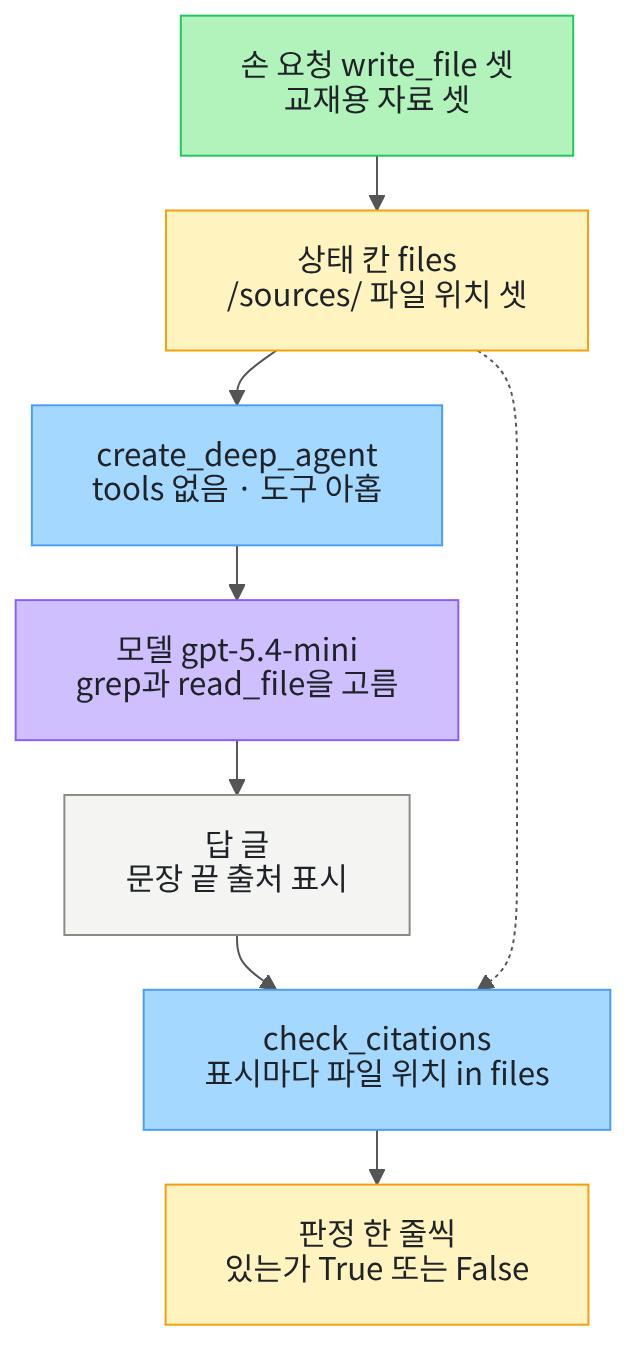

## 1. 준비

제목의 deep research는 여러 자료를 찾아 읽고, 근거를 붙여 답을 쓰는 조사를 뜻합니다.
이 절은 그 조사를 교재가 정한 자료 셋으로 좁혀, 주어진 자료로 하는 조사로 봅니다.
제목 앞부분은 답에 붙인 출처가 실제로 있는 자료를 가리키는지 살핀다는 뜻입니다.
본문에서는 이 일을 출처 확인이라고 부릅니다.
자료는 상태 칸 `files`에 파일로 넣고, 모델은 01절에서 본 기본 파일 도구로 찾습니다.

첫 셀은 패키지 다섯을 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "deepagents==0.7.0" "langchain==1.4.0" "langchain-openai==1.6.0" "langgraph==1.2.11" "python-dotenv==1.2.3"
from importlib.metadata import version

print("deepagents:", version("deepagents"))
print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("langgraph:", version("langgraph"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
deepagents: 0.7.0
langchain: 1.4.0
langchain-openai: 1.6.0


langgraph: 1.2.11
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄 `deepagents: 0.7.0`과 `langgraph: 1.2.11`이 보입니다.
다섯 판 모두 실습 폴더 잠금과 같은 판입니다.
패키지 langgraph는 3절에서 04절의 작은 그래프를 다시 만들려고 설치 목록에 넣었습니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
마지막 가져오기 줄은 앞에서 배운 함수 다섯을 도구 파일 `harness_tools.py`에서 가져옵니다.

In [2]:
# Deep Agents(01절)·상태 형식(04절)·호출 한도(Ch 22)·모델·메시지·그래프 이름을 가져옵니다
from deepagents import create_deep_agent
from deepagents.middleware.filesystem import FilesystemState
from langchain.agents.middleware import ModelCallLimitMiddleware
from langchain.chat_models import init_chat_model
from langchain.messages import AIMessage, HumanMessage
from langgraph.graph import END, START, StateGraph
# 앞 챕터와 01절에서 배운 함수 다섯은 도구 파일에서 가져옵니다(find_source_marks는 이 절에서 도구 파일에 더함)
from harness_tools import estimate_cost, find_source_marks, show_messages, sum_usage, tool_names

print("도구 파일에서 가져온 함수:", "estimate_cost, find_source_marks, show_messages, sum_usage, tool_names")

도구 파일에서 가져온 함수: estimate_cost, find_source_marks, show_messages, sum_usage, tool_names


**결과 읽기** — 출력 줄 `도구 파일에서 가져온 함수: estimate_cost, find_source_marks, show_messages, sum_usage, tool_names`가 보입니다.
네 함수의 뜻은 02절 1절에 적었습니다.
나머지 함수 `find_source_marks`는 Ch 16 01절에서 답의 출처 표시를 뽑으려고 만든 함수입니다.
이 절에서 처음 쓰여, Ch 16 도구 파일의 같은 이름 함수를 글자 그대로 `harness_tools.py`에 더했습니다.

앞에서 배운 함수는 `harness_tools.py`에 모아 두었고, 파일을 열면 코드를 볼 수 있습니다.
커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어 매번 비슷한 답을 고르게 합니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-28에 이 모델로 실행한 결과입니다.
temperature 값을 0으로 두어도, 실행마다 답 문장이 달라질 수 있습니다.
이 셀은 모델 객체만 만들고, 모델 요청은 아직 보내지 않습니다.
모델 요청은 5절 실행 셀에서만 나갑니다.

2~4절은 이 객체로 Deep Agent를 만들기만 하고, 모델을 부르지 않습니다.
이 절은 파일을 디스크에 쓰지 않고, 상태 칸 `files`만 씁니다.

## 2. 조사 에이전트 조립하기

이 절의 조사 에이전트에는 우리 도구를 하나도 주지 않습니다.
그래도 01절 안전 규칙대로, 같은 이름 general-purpose 명세와 바깥 호출 한도는 넣습니다.
다음 셀은 02절 셀과 같은 글의 general-purpose 명세입니다.

In [5]:
# 기본 서브에이전트와 같은 이름의 명세를 만들고, 그 안에 자기 호출 한도 둘을 넣습니다(01절 6절 모양)
helper_limit = ModelCallLimitMiddleware(run_limit=2, exit_behavior="end")
helper_spec = {
    "name": "general-purpose",
    "description": "교재용 도우미입니다. 맡긴 일을 짧게 처리합니다.",
    "system_prompt": "맡긴 일을 두 문장의 한국어로 처리하세요.",
    "middleware": [helper_limit],
}
print("명세의 키:", list(helper_spec))

명세의 키: ['name', 'description', 'system_prompt', 'middleware']


**결과 읽기** — 출력 줄 `명세의 키: ['name', 'description', 'system_prompt', 'middleware']`가 보입니다.
이 명세는 따로 막지 않으면 늘 붙는 기본 general-purpose 서브에이전트의 자리를 바꿉니다.
자기 호출 한도 2가 들어 있어, 모델이 `task`를 부르면 한 번에 요청이 두 번까지만 나갑니다.
01절에서 본 것처럼, 바꾸지 않은 기본 서브에이전트에는 호출 한도가 없습니다.

다음 셀은 03절 셀과 같은 글의 바깥 호출 한도입니다.

In [6]:
# 바깥 에이전트의 모델 요청을 열 번까지로 막는 호출 한도를 만듭니다(02절 셀과 한도만 다름)
outer_limit = ModelCallLimitMiddleware(run_limit=10, exit_behavior="end")
print("바깥 호출 한도:", outer_limit.run_limit)

바깥 호출 한도: 10


**결과 읽기** — 출력 줄 `바깥 호출 한도: 10`이 보입니다.
주석의 「02절 셀과 한도만 다름」은 이 셀을 처음 쓴 03절에서 적은 말입니다.
모델이 `task`를 부르지 않으면, 한 번 실행의 요청 수는 10을 넘지 않습니다.
부르면 부른 횟수 × 2만큼 상한이 커집니다.

다음 셀은 조사 에이전트를 만듭니다.
인자 `tools=`는 넘기지 않고, 우리 시스템 메시지 글에 찾는 차례와 출처 표시 꼴을 적었습니다.

In [7]:
# 새 도구 없이, 우리 시스템 메시지 글·호출 한도·명세를 넘겨 조사 에이전트를 만듭니다(요청은 아직 보내지 않음)
research_text = "자료는 /sources/ 폴더의 파일에만 있습니다. 먼저 grep으로 관련 파일을 찾고, 찾은 파일을 read_file로 읽으세요. 그다음 파일에 적힌 내용만으로 두 문장의 한국어로 답하세요. 답의 문장마다 근거 파일 위치를 [/sources/파일 이름.md] 꼴로 붙이세요."
research_agent = create_deep_agent(
    model=model,
    system_prompt=research_text,
    middleware=[outer_limit],
    subagents=[helper_spec],
)
research_tools = tool_names(research_agent)
print("조사 에이전트의 도구:", research_tools)

조사 에이전트의 도구: ['delete', 'edit_file', 'execute', 'glob', 'grep', 'ls', 'read_file', 'task', 'write_file']


**결과 읽기** — 라벨 `조사 에이전트의 도구:` 뒤에 도구 이름 아홉이 보입니다.
01절에서 본 기본 도구 아홉 그대로이고, 우리가 더한 도구는 없습니다.
찾기에 쓸 `grep`과 읽기에 쓸 `read_file`도 기본 파일 도구 안에 있습니다.
이 에이전트는 파일 도구만으로 자료를 찾게 됩니다.

시스템 메시지 글은 먼저 `grep`으로 찾고 `read_file`로 읽은 뒤 답하라고 적었습니다.
답의 문장마다 파일 위치를 대괄호로 묶어 붙이라고도 적었습니다.
이 대괄호 표시를 4절에서 코드로 판정합니다.

## 3. 교재용 자료를 상태 칸에 넣기

조사할 자료는 웹이 아니라, 교재가 정한 짧은 글 셋입니다.
다음 셀은 자료 셋을 파일 위치마다 적은 딕셔너리입니다.
실제 기관의 글이 아니라, 흐름을 보여 주려고 실행 전에 정한 교재용 글입니다.

In [8]:
# 조사에 쓸 교재용 자료 셋을 파일 위치마다 정합니다(실제 기관의 글이 아님)
source_texts = {
    "/sources/closing-notice.md": "# 서가 정리 휴관 안내\n10월 셋째 주 토요일은 서가 정리로 자료실을 열지 않습니다.\n이날은 대출·연장·반납 창구를 열지 않습니다.",
    "/sources/return-box.md": "# 무인 반납함 안내\n자료실 정문 옆 무인 반납함은 휴관일에도 쓸 수 있습니다.\n반납함에 넣은 책은 다음 운영일에 반납 처리됩니다.",
    "/sources/new-books.md": "# 새로 들어온 책\n이번 달에는 데이터 분석 입문서 세 권이 들어왔습니다.\n새 책은 들어온 날부터 일주일 동안 자료실 안에서만 볼 수 있습니다.",
}
print("자료 파일 위치:", list(source_texts))

자료 파일 위치: ['/sources/closing-notice.md', '/sources/return-box.md', '/sources/new-books.md']


**결과 읽기** — 출력 줄 `자료 파일 위치: ['/sources/closing-notice.md', '/sources/return-box.md', '/sources/new-books.md']`가 보입니다.
첫째는 10월 셋째 주 토요일의 휴관 안내, 둘째는 무인 반납함 안내입니다.
셋째는 새로 들어온 책 소식이라, 반납 질문과는 관계가 적은 자료입니다.
파일 위치는 모두 `/sources/`로 시작하게 정했습니다.

모델이 파일 도구로 이 글을 찾으려면, 글이 상태 칸 `files`에 파일로 있어야 합니다.
04절에서 본 것처럼, 파일 항목에는 글 말고도 만든 시각 같은 칸이 있습니다.
그래서 항목을 손으로 만들지 않고, 06절처럼 손 요청 `write_file`로 적습니다.
다음 셀은 04절 3절 셀과 같은 글의 작은 그래프 함수입니다.

In [9]:
# Deep Agent 하나를 받아, 그 도구 실행 노드 하나만 든 작은 그래프를 만들어 내놓습니다(상태 형식은 files 칸이 있는 FilesystemState)
def tools_only_graph(agent):
    builder = StateGraph(FilesystemState)
    builder.add_node("tools", agent.nodes["tools"].bound)
    builder.add_edge(START, "tools")
    builder.add_edge("tools", END)
    return builder.compile()

**결과 읽기** — 정의 셀이라 출력이 없습니다.
작은 그래프에는 도구 실행 노드 하나뿐이라, 손 요청을 넣어도 모델을 부르지 않습니다.

다음 셀은 조사 에이전트의 도구 실행 노드로 작은 그래프를 만듭니다.

In [10]:
# 조사 에이전트의 도구 실행 노드만 든 작은 그래프를 만듭니다(요청은 보내지 않음)
small_graph = tools_only_graph(research_agent)
small_nodes = small_graph.get_graph().nodes
print("작은 그래프의 노드:", list(small_nodes))

작은 그래프의 노드: ['__start__', 'tools', '__end__']


**결과 읽기** — 출력 줄 `작은 그래프의 노드: ['__start__', 'tools', '__end__']`가 보입니다.
도구 실행 노드에는 조사 에이전트의 도구 아홉이 그대로 들어 있습니다.

다음 셀은 자료마다 `write_file` 요청을 하나씩 손으로 만들어, 한 응답에 셋을 담습니다.
Ch 19 05절에서 본 것처럼, 한 응답에 도구 요청이 여럿 들어갈 수 있습니다.
호출 ID는 `hand_` 뒤에 파일 위치를 붙여 우리가 정했습니다.

In [11]:
# 모델 없이, 자료마다 write_file 요청을 손으로 만들어 한 응답에 담고 작은 그래프에 넣습니다
write_calls = []
for path in source_texts:
    write_args = {"file_path": path, "content": source_texts[path]}
    write_calls.append({"name": "write_file", "args": write_args, "id": "hand_" + path, "type": "tool_call"})
write_request = AIMessage(content="", tool_calls=write_calls)
write_result = small_graph.invoke({"messages": [write_request]})
source_files = write_result["files"]
show_messages(write_result["messages"])
print("상태 칸 files의 파일 위치:", list(source_files))

AIMessage | 도구 호출 요청: ['write_file', 'write_file', 'write_file']
ToolMessage | 결과 상태: success | 내용: Updated file /sources/closing-notice.md
ToolMessage | 결과 상태: success | 내용: Updated file /sources/return-box.md
ToolMessage | 결과 상태: success | 내용: Updated file /sources/new-books.md
상태 칸 files의 파일 위치: ['/sources/closing-notice.md', '/sources/return-box.md', '/sources/new-books.md']


**결과 읽기** — `AIMessage` 줄 뒤에 `ToolMessage` 줄 셋이 보이고, 결과 상태는 모두 `success`입니다.
내용 `Updated file /sources/closing-notice.md`처럼, 파일마다 적었다는 글이 왔습니다.
라벨 `상태 칸 files의 파일 위치:` 뒤에 자료 셋의 위치가 있습니다.
이 셀까지 모델 요청은 0번입니다.

이 상태 칸을 `source_files`라는 이름으로 두고, 뒤에서 조사 에이전트의 입력에 넣습니다.
다음 셀은 모델이 쓸 두 도구를 먼저 손으로 불러 봅니다.
도구 `grep`은 글에 낱말이 든 파일을 찾고, `read_file`은 파일 하나의 글을 읽습니다.

In [12]:
# 모델 없이, grep 요청 하나와 read_file 요청 하나를 손으로 만들어 자료가 든 상태와 함께 넣습니다
grep_call = {"name": "grep", "args": {"pattern": "휴관"}, "id": "hand_grep_1", "type": "tool_call"}
read_args = {"file_path": "/sources/return-box.md"}
read_call = {"name": "read_file", "args": read_args, "id": "hand_read_1", "type": "tool_call"}
find_request = AIMessage(content="", tool_calls=[grep_call, read_call])
find_result = small_graph.invoke({"messages": [find_request], "files": source_files})
show_messages(find_result["messages"])

AIMessage | 도구 호출 요청: ['grep', 'read_file']
ToolMessage | 결과 상태: success | 내용: /sources/closing-notice.md
/sources/return-box.md
ToolMessage | 결과 상태: success | 내용: 1  # 무인 반납함 안내
2  자료실 정문 옆 무인 반납함은 휴관일에도 쓸 수 있습니다.
3  반납함에 넣은 책은 다음 운영일에 반납 처리됩니다.


**결과 읽기** — 첫 `ToolMessage` 줄의 내용은 파일 위치 둘 `/sources/closing-notice.md`와 `/sources/return-box.md`입니다.
낱말 「휴관」이 든 파일만 나왔고, 새 책 소식은 나오지 않았습니다.
둘째 `ToolMessage` 줄의 내용은 무인 반납함 안내의 세 줄이고, 줄마다 앞에 줄 번호가 붙었습니다.

설치판 `middleware/filesystem.py` 912~915행에서 `grep`의 기본 출력은 파일 위치 목록입니다.
1012~1016행의 설명 글대로, 넣은 낱말은 정규식이 아니라 글자 그대로 찾습니다.
그래서 모델이 고른 낱말이 자료의 글과 글자까지 맞아야 파일이 나옵니다.
이 두 도구를 쓸지, 무엇을 찾을지는 5절에서 모델이 정합니다.

## 4. 출처를 코드로 확인하기

답 글에 붙은 출처 표시가 실제로 있는 파일을 가리키는지, 코드로 판정해 봅니다.
Ch 16 01절에서는 답의 출처 표시를 뽑아, 검색 결과로 만든 허용 목록과 대조했습니다.
이 절에서는 허용 목록 자리에 상태 칸 `files`를 둡니다.
다음 셀은 출처 표시 둘을 붙인 답 글을 손으로 만들고, Ch 16 01절 함수로 표시를 뽑습니다.
둘째 표시의 파일 위치는 자료 셋에 없는 이름으로 일부러 적었습니다.

In [13]:
# 모델 없이, 출처 표시 둘을 붙인 답 글을 손으로 만들고 Ch 16 01절 함수 find_source_marks로 표시를 뽑습니다
sample_answer = "그날은 자료실 창구를 열지 않습니다[/sources/closing-notice.md]. 책은 정문 옆 무인 반납함에 넣으면 됩니다[/sources/return-guide.md]."
sample_marks = find_source_marks(sample_answer)
print("뽑은 출처 표시:", sample_marks)

뽑은 출처 표시: ['[/sources/closing-notice.md]', '[/sources/return-guide.md]']


**결과 읽기** — 출력 줄 `뽑은 출처 표시: ['[/sources/closing-notice.md]', '[/sources/return-guide.md]']`가 보입니다.
함수 `find_source_marks`는 글을 여는 대괄호로 나누고, 닫는 대괄호 앞까지를 표시로 모읍니다.
표시는 대괄호까지 붙은 글이라, 파일 위치와 견주려면 대괄호 둘을 빼야 합니다.

다음 셀은 이 절에서 새로 만드는 판정 함수입니다.
표시마다 대괄호를 뺀 파일 위치가 둘째 인자 안에 있는지 `in`으로 봅니다.
둘째 인자가 딕셔너리면 키에서 찾고, 목록이면 항목에서 찾습니다.

In [14]:
# 답 글의 출처 표시마다 대괄호를 뺀 파일 위치가 known 안에 있는지 판정해, 한 줄씩 모아 내놓습니다
def check_citations(answer, known):
    rows = []
    for mark in find_source_marks(answer):
        # 첫 글자와 마지막 글자(대괄호 둘)를 뺀 글이 인용한 파일 위치입니다
        cited = mark[1:-1]
        rows.append({"인용": cited, "있는가": cited in known})
    return rows

**결과 읽기** — 정의 셀이라 출력이 없습니다.
자르기 `mark[1:-1]`은 첫 글자와 마지막 글자를 뺀 글이고, 음수 자리는 Ch 16 03절에서 배웠습니다.
판정 한 줄은 인용한 파일 위치와 `있는가` 값을 담은 딕셔너리입니다.
이 함수는 파일이 있는지만 보고, 파일의 글은 읽지 않습니다.

다음 셀은 앞에서 만든 답 글을 3절의 상태 칸 `files`로 판정합니다.

In [15]:
# 손으로 만든 답 글을, 3절에서 자료를 넣은 상태 칸 files로 판정합니다
sample_rows = check_citations(sample_answer, source_files)
print("판정 결과:")
for row in sample_rows:
    print(row)

판정 결과:
{'인용': '/sources/closing-notice.md', '있는가': True}
{'인용': '/sources/return-guide.md', '있는가': False}


**결과 읽기** — 라벨 줄 아래 첫 줄은 `{'인용': '/sources/closing-notice.md', '있는가': True}`입니다.
둘째 줄은 `{'인용': '/sources/return-guide.md', '있는가': False}`입니다.
그럴듯한 이름이어도, 상태 칸에 없는 파일을 가리킨 표시는 `False`로 드러납니다.
모델 없이 손으로 만든 글이라, 이 판정은 몇 번 실행해도 같습니다.

다음 셀은 판정 함수에 두 가지 글을 더 넣어 봅니다.
하나는 출처 표시가 없는 글이고, 다른 하나는 있는 파일 하나만 인용한 글입니다.
실행 전에 예상해 봅니다.
출처 표시가 없으면 무엇이 나올까요?

In [16]:
# 값 바꿔 보기: 출처 표시가 없는 글과, 있는 파일 하나만 인용하고 다른 자료를 빠뜨린 글을 판정합니다
no_mark_answer = "그날은 정문 옆 무인 반납함에 넣으면 됩니다."
partial_answer = "그날은 빌린 책을 반납할 수 없습니다[/sources/closing-notice.md]."
print("출처 표시가 없는 글:", check_citations(no_mark_answer, source_files))
print("다른 자료를 빠뜨린 글:", check_citations(partial_answer, source_files))

출처 표시가 없는 글: []
다른 자료를 빠뜨린 글: [{'인용': '/sources/closing-notice.md', '있는가': True}]


**결과 읽기** — 출력 줄 `출처 표시가 없는 글: []`가 보입니다.
표시가 없으면 판정할 것이 없어 빈 목록이 나오고, `False`도 나오지 않습니다.
출력 줄 `다른 자료를 빠뜨린 글: [{'인용': '/sources/closing-notice.md', '있는가': True}]`도 보입니다.
이 글은 반납할 수 없다고 적었지만, 3절의 무인 반납함 안내는 휴관일에도 쓸 수 있다고 적습니다.
그래도 판정은 `True`입니다.

이 함수가 보는 것은 인용한 파일이 상태 칸에 있는가 하나뿐입니다.
빈 목록은 판정을 통과했다는 뜻이 아니라, 인용이 하나도 없다는 뜻입니다.
글이 파일 내용과 맞는지, 빠뜨린 자료가 있는지는 이 판정이 보지 않습니다.
그 일은 Ch 15 02절의 근거 충실도처럼 글을 견주는 평가가 맡습니다.

## 5. 실제 모델로 조사하기

이제 조사 에이전트에 3절의 상태 칸과 질문 한 줄을 넣어 한 번 실행합니다.
질문은 10월 셋째 주 토요일에 빌린 책을 반납할 수 있는지 묻습니다.
자료 셋 가운데 휴관 안내와 무인 반납함 안내가 이 질문과 관계가 있습니다.
실행 전에 예상해 봅니다.
모델은 `grep`으로 찾고 `read_file`로 읽은 뒤, 출처 표시를 붙여 답할 것입니다.

In [17]:
# 3절 자료가 든 상태 칸 files와 질문 한 줄을 함께 넣어 한 번 실행합니다
question = "10월 셋째 주 토요일에 빌린 책을 반납할 수 있나요?"
first_input = {"messages": [HumanMessage(content=question)], "files": source_files}
input_count = len(first_input["messages"])
run_result = research_agent.invoke(first_input)
run_messages = run_result["messages"]
print("결과 메시지 수:", len(run_messages))

결과 메시지 수: 6


**결과 읽기** — 라벨 `결과 메시지 수:` 뒤에 결과 메시지 수가 보입니다.
넣은 질문 하나 뒤에, 모델의 응답과 도구 메시지가 더해졌습니다.

이번 실행에서는 `결과 메시지 수: 6`이었습니다.
질문 하나 뒤에 `grep` 요청 응답, 도구 메시지, `read_file` 요청 응답, 도구 메시지, 마지막 답이 더해졌습니다.
노트북 밖 다섯 번과 새 커널 두 번에서도 모두 여섯이었습니다.

다음 셀은 Ch 19 06절 함수 `show_messages`로 결과 메시지를 차례로 봅니다.

In [18]:
# 결과 메시지를 차례로 봅니다(Ch 19 06절 함수 show_messages)
print("결과 메시지:")
show_messages(run_messages)

결과 메시지:
HumanMessage
AIMessage | 도구 호출 요청: ['grep']
ToolMessage | 결과 상태: success | 내용: /sources/closing-notice.md:
  2: 10월 셋째 주 토요일은 서가 정리로 자료실을 열지 않습니다.
AIMessage | 도구 호출 요청: ['read_file']
ToolMessage | 결과 상태: success | 내용: 1  # 서가 정리 휴관 안내
2  10월 셋째 주 토요일은 서가 정리로 자료실을 열지 않습니다.
3  이날은 대출·연장·반납 창구를 열지 않습니다.
AIMessage | 도구 호출 요청: []


**결과 읽기** — 라벨 줄 아래가 결과 메시지의 차례입니다.
`AIMessage` 줄에는 모델이 요청한 도구 이름이, `ToolMessage` 줄에는 도구가 낸 글이 보입니다.
마지막 `AIMessage` 줄은 도구 요청이 없는 응답이고, 모델이 쓴 답입니다.

이번 실행에서 모델은 `grep`과 `read_file`을 한 응답에 하나씩 요청한 뒤 답했습니다.
노트북 밖 다섯 번과 새 커널 두 번에서 모두 이 차례였습니다.
다만 `grep` 도구 메시지의 모양은 실행마다 달랐습니다.
교재 출력에서는 찾은 줄까지 보였고, 새 커널 두 번째에서는 파일 위치만 보였습니다.
설치판 912~915행에서 이 모양은 모델이 채우는 인자 `output_mode`로 정해집니다.

다음 셀은 응답에 담긴 도구 요청에서 인자 값을 모으는 함수입니다.

In [19]:
# 메시지 목록의 응답에서, 이름이 tool_name인 도구 요청마다 인자 arg_name의 값을 차례로 모아 내놓습니다
def call_args(messages, tool_name, arg_name):
    values = []
    for message in messages:
        if type(message).__name__ == "AIMessage":
            for call in message.tool_calls:
                if call["name"] == tool_name:
                    values.append(call["args"][arg_name])
    return values

**결과 읽기** — 정의 셀이라 출력이 없습니다.
도구 요청 하나는 Ch 19 04절에서 본 칸 `name`·`args`·`id`를 가진 딕셔너리입니다.
이 함수는 이름이 맞는 요청마다 인자 딕셔너리에서 값 하나를 꺼내 목록에 붙입니다.

다음 셀은 이 함수로 `grep`에 넣은 낱말과 `read_file`로 읽은 파일 위치를 모읍니다.

In [20]:
# 이번 실행이 더한 응답에서, grep에 넣은 낱말과 read_file로 읽은 파일 위치를 모읍니다
run_new = run_messages[input_count:]
grep_patterns = call_args(run_new, "grep", "pattern")
read_paths = call_args(run_new, "read_file", "file_path")
print("grep에 넣은 낱말:", grep_patterns)
print("read_file로 읽은 파일 위치:", read_paths)

grep에 넣은 낱말: ['10월 셋째 주 토요일']
read_file로 읽은 파일 위치: ['/sources/closing-notice.md']


**결과 읽기** — 라벨 `grep에 넣은 낱말:`과 `read_file로 읽은 파일 위치:` 뒤에 목록이 하나씩 보입니다.
모델이 무엇을 찾고 어느 파일을 읽을지 정한 값입니다.

이번 실행에서는 `grep에 넣은 낱말: ['10월 셋째 주 토요일']`, `read_file로 읽은 파일 위치: ['/sources/closing-notice.md']`였습니다.
노트북 밖 다섯 번과 새 커널 두 번에서 모두 휴관 안내 하나만 읽었습니다.
이 낱말은 무인 반납함 안내의 글에 없어, 그 파일은 `grep` 결과에 나오지 않았습니다.
무엇을 찾을지는 모델이 정하는 값이라, 실행마다 달라질 수 있습니다.

다음 셀은 모델이 쓴 마지막 답 글을 봅니다.

In [21]:
# 모델이 쓴 마지막 답 글을 봅니다(실행마다 달라질 수 있는 값)
answer_text = run_messages[-1].text
print("마지막 답 글:")
print(answer_text)

마지막 답 글:
아니요, 10월 셋째 주 토요일에는 자료실을 열지 않아서 대출·연장·반납 창구도 운영하지 않습니다. [/sources/closing-notice.md]  
따라서 그날은 빌린 책을 반납할 수 없습니다. [/sources/closing-notice.md]


**결과 읽기** — 라벨 `마지막 답 글:` 아래가 모델이 쓴 답입니다.
문장 끝에 대괄호로 묶은 파일 위치가 붙었는지 봅니다.

이번 실행의 답은 그날 자료실을 열지 않아 반납할 수 없다고 적었고, 휴관 안내의 파일 위치를 붙였습니다.
3절에서 본 무인 반납함 안내는 휴관일에도 반납함을 쓸 수 있다고 적습니다.
모델이 그 파일을 읽지 않아, 답에 그 내용이 들어가지 않았습니다.
교재 출력의 답은 두 문장에 표시를 하나씩, 새 커널 두 번째의 답은 끝에 표시 하나를 붙였습니다.
답 글은 실행마다 달라질 수 있어 결론에 쓰지 않습니다.

다음 셀은 실행 뒤 상태 칸 `files`를 봅니다.
판정 함수에 넣기 전에, 모델이 새 파일을 적지 않았는지 먼저 봅니다.

In [22]:
# 실행 뒤 상태 칸 files의 파일 위치가 3절에서 넣은 자료와 같은지 봅니다
after_paths = list(run_result["files"])
print("실행 뒤 상태 칸 files의 파일 위치:", after_paths)
print("넣은 자료와 같은가:", after_paths == list(source_files))

실행 뒤 상태 칸 files의 파일 위치: ['/sources/closing-notice.md', '/sources/return-box.md', '/sources/new-books.md']
넣은 자료와 같은가: True


**결과 읽기** — 라벨 `실행 뒤 상태 칸 files의 파일 위치:` 뒤에 파일 위치 목록이 보입니다.
라벨 `넣은 자료와 같은가:` 뒤의 값으로, 3절에서 넣은 셋과 같은지 봅니다.

이번 실행에서는 `넣은 자료와 같은가: True`였고, 모델은 `write_file`을 부르지 않았습니다.
노트북 밖 다섯 번과 새 커널 두 번에서도 같았습니다.
모델이 파일을 새로 적으면 그 파일도 상태 칸에 있어, 판정에서 `True`가 됩니다.

다음 셀은 답 글의 출처 표시를 실행 뒤 상태 칸 `files`로 판정합니다.

In [23]:
# 마지막 답 글의 출처 표시를, 실행 뒤 상태 칸 files로 판정합니다
answer_rows = check_citations(answer_text, run_result["files"])
print("상태 칸 files로 본 판정:")
for row in answer_rows:
    print(row)

상태 칸 files로 본 판정:
{'인용': '/sources/closing-notice.md', '있는가': True}
{'인용': '/sources/closing-notice.md', '있는가': True}


**결과 읽기** — 라벨 `상태 칸 files로 본 판정:` 아래에 출처 표시마다 판정 한 줄이 보입니다.
출처 표시가 없으면 라벨 줄만 나옵니다.

이번 실행의 판정은 모두 `True`였고, 줄 수는 실행마다 달랐습니다.
교재 출력은 같은 파일 위치를 두 번 인용해 두 줄, 새 커널 두 번째는 한 줄이었습니다.
노트북 밖 다섯 번에서는 네 번이 한 줄, 한 번이 두 줄이었습니다.
4절에서 본 것처럼, `True`는 인용한 파일이 상태 칸에 있다는 뜻일 뿐입니다.
판정 결과는 모델 글에서 나온 값이라 결론에 쓰지 않습니다.

다음 셀은 같은 답 글을, 모델이 `read_file`로 읽은 파일 위치 목록으로 판정합니다.
상태 칸에 있어도 모델이 읽지 않은 파일을 인용했다면, 그 문장은 따로 살펴야 합니다.

In [24]:
# 같은 답 글을, 모델이 read_file로 읽은 파일 위치 목록으로도 판정합니다
read_rows = check_citations(answer_text, read_paths)
print("읽은 파일 위치로 본 판정:")
for row in read_rows:
    print(row)

읽은 파일 위치로 본 판정:
{'인용': '/sources/closing-notice.md', '있는가': True}
{'인용': '/sources/closing-notice.md', '있는가': True}


**결과 읽기** — 라벨 `읽은 파일 위치로 본 판정:` 아래에 같은 모양의 판정이 보입니다.
여기서 `True`는 인용한 파일을 모델이 이번 실행에서 읽었다는 뜻입니다.
판정 함수는 그대로 두고, 둘째 인자만 딕셔너리에서 목록으로 바꿨습니다.

이번 실행에서도 판정은 모두 `True`였습니다.
인용한 파일은 모두 모델이 읽은 휴관 안내였다는 뜻입니다.
읽지 않은 무인 반납함 안내는 인용되지 않았으니, 이 판정에도 나타나지 않습니다.

## 6. 요청 수와 예상 비용

서브에이전트를 부르지 않았다면, 결과 메시지의 응답 수가 이번 실행의 요청 수 전부입니다.
다음 셀은 도구를 요청한 응답 수와 `task` 요청 수를 셉니다.

In [25]:
# 이번 실행이 더한 응답 가운데 도구를 요청한 응답 수와, task 요청 수를 셉니다
tool_replies = 0
for message in run_new:
    if type(message).__name__ == "AIMessage":
        if len(message.tool_calls) > 0:
            tool_replies = tool_replies + 1
task_types = call_args(run_new, "task", "subagent_type")
print("도구를 요청한 응답 수:", tool_replies)
print("task 요청 수:", len(task_types))

도구를 요청한 응답 수: 2
task 요청 수: 0


**결과 읽기** — 라벨 `도구를 요청한 응답 수:`와 `task 요청 수:` 뒤에 수가 하나씩 보입니다.
도구 `task` 요청이 0이면 서브에이전트 요청이 없으니, 결과 메시지만 세면 됩니다.

이번 실행에서는 `도구를 요청한 응답 수: 2`, `task 요청 수: 0`이었습니다.
노트북 밖 다섯 번과 새 커널 두 번에서도 같았고, 서브에이전트 요청은 없었습니다.

다음 셀은 Ch 19 05절 함수 `sum_usage`로 요청 수와 토큰을 셉니다.
02절에서 본 셈대로, 요청 수가 도구를 요청한 응답 수에 1을 더한 값인지도 봅니다.

In [26]:
# 이번 실행이 더한 메시지만 Ch 19 05절 함수 sum_usage로 세고, 도구를 요청한 응답 수 + 1과 견줍니다
run_usage = sum_usage(run_new)
print("요청 수:", run_usage["requests"])
print("도구를 요청한 응답 수 + 1과 같은가:", run_usage["requests"] == tool_replies + 1)
print("입력 토큰:", run_usage["input_tokens"], "| 출력 토큰:", run_usage["output_tokens"])

요청 수: 3
도구를 요청한 응답 수 + 1과 같은가: True
입력 토큰: 5917 | 출력 토큰: 139


**결과 읽기** — 출력 줄 `도구를 요청한 응답 수 + 1과 같은가: True`가 보입니다.
모델은 도구 결과를 받을 때마다 다시 요청을 받고, 도구 요청이 없는 응답에서 멈춥니다.
그래서 호출 한도에 닿지 않은 실행의 요청 수는 이 셈과 같습니다.

이번 실행에서는 `요청 수: 3`, `입력 토큰: 5917 | 출력 토큰: 139`였습니다.
새 커널 두 번째는 입력 5867·출력 125로, 토큰은 실행마다 조금씩 달랐습니다.
요청 수 3은 노트북 밖 다섯 번과 새 커널 두 번에서 모두 같았습니다.

다음 셀은 02절 셀과 같은 글로 예상 비용을 셉니다.

In [27]:
# 2026-09-17 요금표(100만 토큰당 달러)로 이번 실행의 예상 비용을 셉니다(Ch 6 06절 함수 estimate_cost)
input_rate = 0.75
cached_input_rate = 0.075
output_rate = 4.50
run_cost = estimate_cost(run_usage, input_rate, cached_input_rate, output_rate)
rounded_cost = round(run_cost, 6)
print("예상 비용(달러):", rounded_cost)

예상 비용(달러): 0.005063


**결과 읽기** — 라벨 `예상 비용(달러):` 뒤에 어림값이 보입니다.
입력 토큰을 모두 입력 요금으로 센 어림이고, 청구 금액이 아닙니다.

이번 실행에서는 `예상 비용(달러): 0.005063`이었습니다.
새 커널 두 번째는 0.004963달러였고, 노트북 밖 다섯 번은 0.004954에서 0.005063달러 사이였습니다.

## 정리

1. 교재용 자료를 손 요청 `write_file`로 상태 칸 `files`에 넣으면, 새 도구 없이 기본 파일 도구로 찾을 수 있습니다.
2. 출처 표시가 상태 칸에 있는 파일을 가리키는지는 `in`으로 판정하고, 없는 파일은 `False`로 드러납니다.
3. 이 판정은 파일이 있는지만 보므로, 빠뜨린 자료와 글의 내용은 따로 살펴야 합니다.

08절에서는 앞 절들의 기능을 한 흐름에서 함께 실행하고, 운영에서 남는 한계를 봅니다.